In [92]:
!pip install bs4 requests matplotlib yfinance

In [93]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

In [94]:
# function to plot graph
def make_graph(stock_data, revenue_data, stock):
  stock_data_filtered = stock_data[stock_data.Date <= '2021-06-04']
  revenue_data_filtered = revenue_data[revenue_data.Date <= '2021-04-30']

  fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex = True)
  # stock price
  axes[0].plot(pd.to_datetime(stock_data_filtered.Date), stock_data_filtered.Close.astype(float), label = 'Share Price', color = 'blue')
  axes[0].set_ylabel('Price in USD')
  axes[0].set_title(f'{stock} historical share price')

  # revenue
  axes[1].plot(pd.to_datetime(revenue_data_filtered.Date), revenue_data_filtered.Revenue.astype(float), label = 'Revenue', color = 'blue')
  axes[1].set_ylabel('Revenue in Million USD')
  axes[1].set_title(f'{stock} historical revenue')

  plt.tight_layout()
  plt.show()

The above function plots 2 graphs for a given company. The first graph is date vs stock price and the second is date vs revenue.

First, the stock price and revenue DataFrames are filtered to only show data before specific dates. Then, the figure area is created using the subplot function. The figure area has 2 rows and 1 column, and both graphs share x scale, aligning both the x axes. Next, the graphs are plotted. Tight layout adjusts the layout and spacing so nothing overlaps or gets cut off.

### Extracting Tesla stock prices using **yfinance**

In [95]:
# tesla data
tesla = yf.Ticker('TSLA')

In [96]:
tesla_data = tesla.history(period = 'max')

In [97]:
tesla_data.reset_index(inplace=True)
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


### Extracting Tesla's revenue data from a URL using **BeautifulSoup** and **Requests**

In [98]:
tesla_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm'
tesla_revenue_html = requests.get(tesla_url).text

In [99]:
tesla_revenue_soup = BeautifulSoup(tesla_revenue_html,'html.parser')

In [100]:
# creating DataFrame from the quarterly revenue table on the website
new_rows = list()
tesla_quarterly_revenue = tesla_revenue_soup.find_all('tbody')[1]
for row in tesla_revenue_soup.find_all('tbody')[1].find_all('tr'):
    col = row.find_all('td')
    new_rows.append({
        'Date':col[0].text,
        'Revenue':col[1].text
    })
    tesla_revenue = pd.DataFrame(new_rows)

In [101]:
tesla_revenue.head()

,Date,Revenue
0,2022-09-30,"$21,454"
1,2022-06-30,"$16,934"
2,2022-03-31,"$18,756"
3,2021-12-31,"$17,719"
4,2021-09-30,"$13,757"


In [102]:
tesla_revenue.tail()

,Date,Revenue
49,2010-06-30,$28
50,2010-03-31,$21
51,2009-12-31,
52,2009-09-30,$46
53,2009-06-30,$27


There are null values in the revenue column and there is a dollar sign and commas. Let's do a little bit of data cleaning to fix that

In [103]:

tesla_revenue['Revenue'] = tesla_revenue['Revenue'].str.replace(',|\$',"",regex=True) # removing $ and ,

<>:1: SyntaxWarning: invalid escape sequence '\$'
<>:1: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_821/3414791136.py:1: SyntaxWarning: invalid escape sequence '\$'
  tesla_revenue['Revenue'] = tesla_revenue['Revenue'].str.replace(',|\$',"",regex=True) # removing $ and ,


In [104]:
tesla_revenue.dropna(inplace = True) # removing nulls

In [105]:
tesla_revenue.tail()

,Date,Revenue
49,2010-06-30,28
50,2010-03-31,21
51,2009-12-31,
52,2009-09-30,46
53,2009-06-30,27


In [106]:
# there's still an empty cell which could be because it's not a null value but an empty string
tesla_revenue['Revenue'] = tesla_revenue['Revenue'].replace('', None)
tesla_revenue.dropna(inplace=True)

In [107]:
tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


In [108]:
# gamestop
gamestop = yf.Ticker('GME')

In [109]:
gme_data = gamestop.history(period='max')

In [110]:
gme_data.reset_index(inplace=True)
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712708,1.716074,1.670626,1.683251,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658001,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


In [111]:
# webscraping to get revenue data
gme_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html'
gme_revenue_html = requests.get(gme_url).text

In [112]:
gme_revenue_soup = BeautifulSoup(gme_revenue_html,'html.parser')

In [113]:
# extracting the required table and storing it into a dataframe
new_rows_2 = list()
for row in gme_revenue_soup.find_all('tbody')[1].find_all('tr'):
  col = row.find_all('td')
  new_rows_2.append({
      'Date':col[0].text,
      'Revenue':col[1].text
  })
  gamestop_revenue = pd.DataFrame(new_rows_2)

In [114]:
gamestop_revenue.head()

,Date,Revenue
0,2020-04-30,"$1,021"
1,2020-01-31,"$2,194"
2,2019-10-31,"$1,439"
3,2019-07-31,"$1,286"
4,2019-04-30,"$1,548"


In [115]:
gamestop_revenue.tail()

,Date,Revenue
57,2006-01-31,"$1,667"
58,2005-10-31,$534
59,2005-07-31,$416
60,2005-04-30,$475
61,2005-01-31,$709


In [116]:
# let's perform the same cleaning for this DataFrame
gamestop_revenue['Revenue'] = gamestop_revenue['Revenue'].str.replace(',|\$',"",regex=True)
gamestop_revenue['Revenue'] = gamestop_revenue['Revenue'].replace('', None)
gamestop_revenue.dropna(inplace=True)

<>:2: SyntaxWarning: invalid escape sequence '\$'
<>:2: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_821/3894056248.py:2: SyntaxWarning: invalid escape sequence '\$'
  gamestop_revenue['Revenue'] = gamestop_revenue['Revenue'].str.replace(',|\$',"",regex=True)


In [117]:
gamestop_revenue.head()

,Date,Revenue
0,2020-04-30,1021
1,2020-01-31,2194
2,2019-10-31,1439
3,2019-07-31,1286
4,2019-04-30,1548


In [118]:
gamestop_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


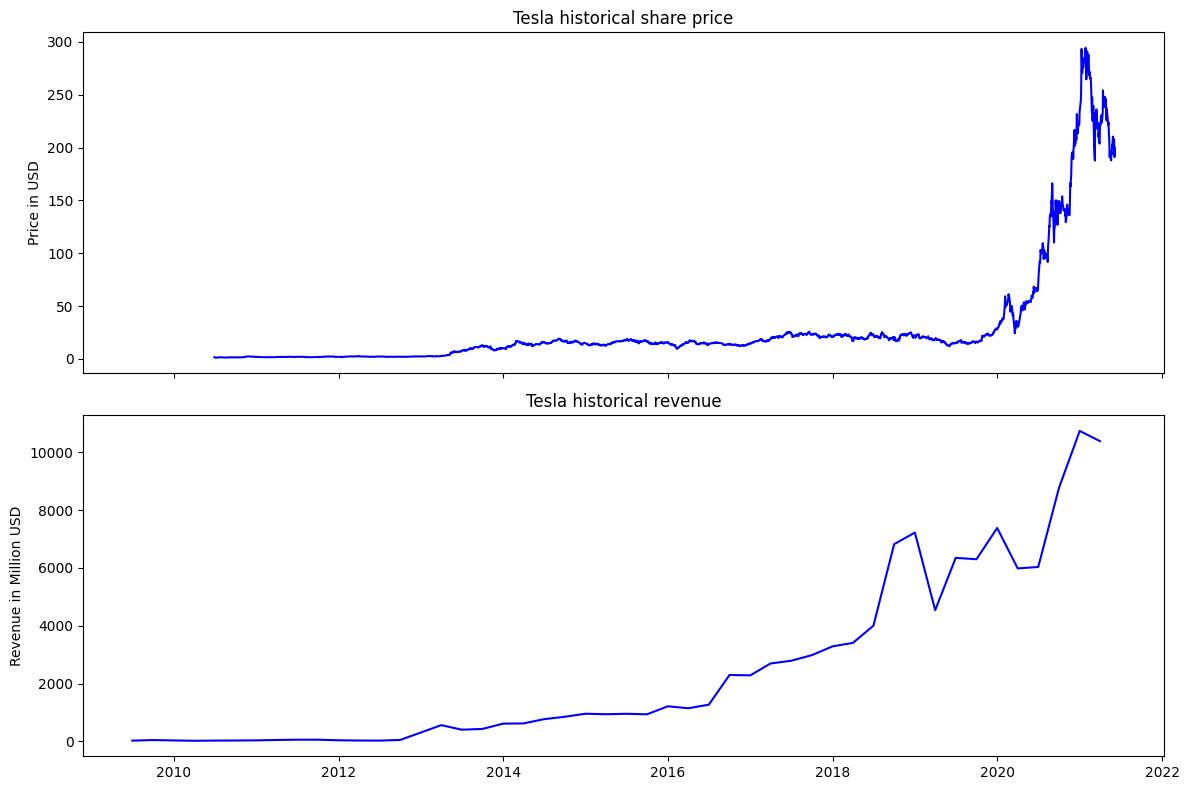

In [119]:
# plotting graphs for both companies
make_graph(tesla_data, tesla_revenue, 'Tesla')

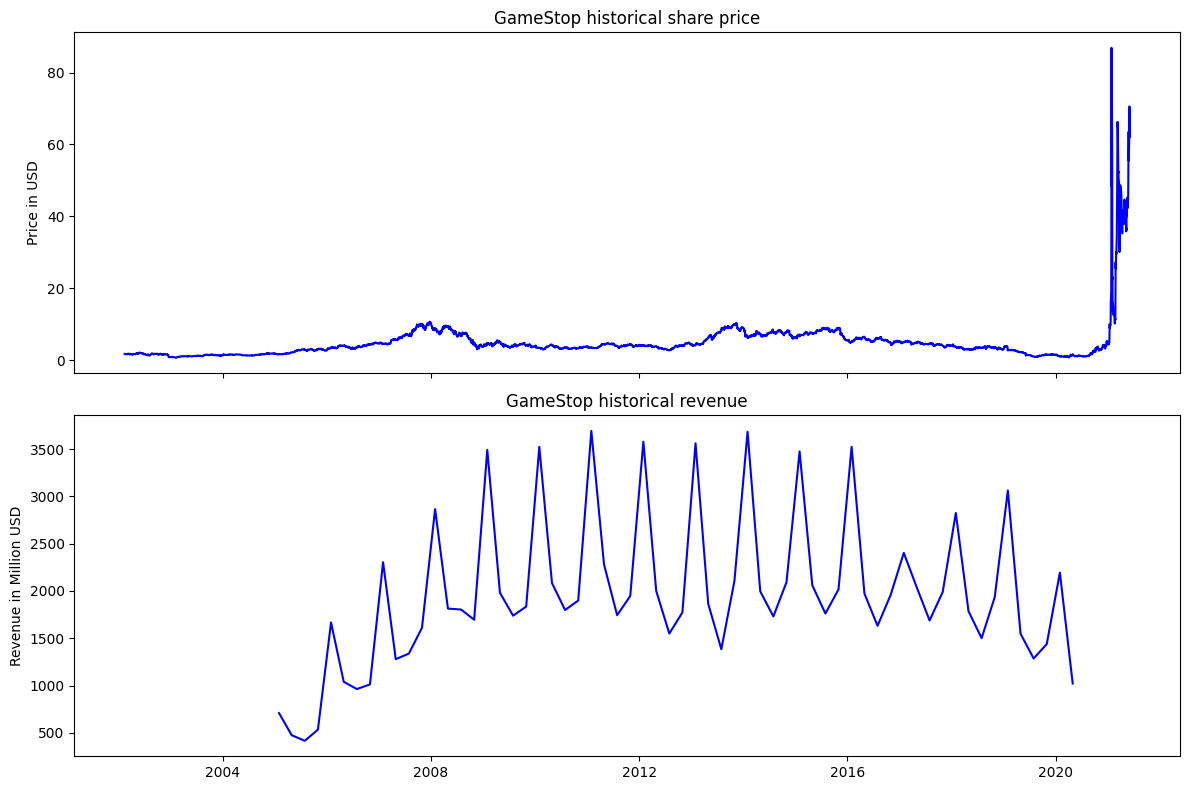

In [120]:
make_graph(gme_data, gamestop_revenue, 'GameStop')